### EN3160 Assignment 2 on Fitting and Alignment 
### 230680M - W.M.H. Wanigasundara

### Problem 1

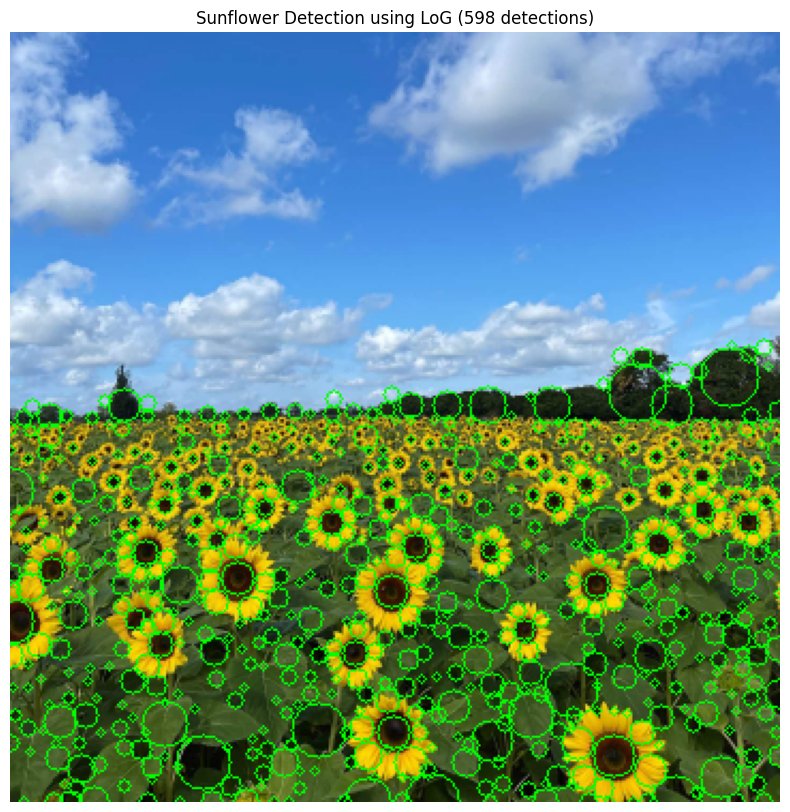

Largest detected circles
----------------------------------------------------------
     X      Y     Radius      Sigma     Response
   293    168      14.14      10.00      0.93169
   336    161      14.14      10.00      0.89016
   197    359      13.44       9.50      0.76663
   144    326      13.44       9.50      0.66596
   262    307      12.73       9.00      0.52573
    90    341      12.73       9.00      0.44441
   311    359      12.02       8.50      0.70863
   278    232      11.31       8.00      0.55077
     0    275      10.61       7.50      1.37536
   167    359      10.61       7.50      0.61152

Sigma range used: 1.50 to 10.00
Total detections: 598


In [29]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

image_path = "images/the_berry_farms_sunflower_field.jpeg"
im = cv2.imread(image_path, cv2.IMREAD_REDUCED_COLOR_4)

if im is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

im_rgb = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
im_hsv = cv2.cvtColor(im, cv2.COLOR_BGR2HSV)

# Mask yellow sunflower petals
lower_yellow = np.array([15, 70, 60], dtype=np.uint8)
upper_yellow = np.array([40, 255, 255], dtype=np.uint8)
yellow_mask = cv2.inRange(im_hsv, lower_yellow, upper_yellow)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 21))
candidate_mask = cv2.dilate(yellow_mask, kernel)

gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY).astype(np.float32) / 255.0
sigmas = np.linspace(1.5, 10.0, 18)
responses = []

# Compute scale-normalized LoG responses
for sigma in sigmas:
    blurred = cv2.GaussianBlur(gray, (0, 0), sigmaX=float(sigma))
    laplacian = cv2.Laplacian(blurred, cv2.CV_32F, ksize=3)
    responses.append((sigma ** 2) * np.abs(laplacian))

responses = np.stack(responses, axis=0)
local_max = maximum_filter(responses, size=(3, 7, 7))
extrema_mask = (
    (responses == local_max)
    & (responses > 0.015)
    & (candidate_mask[None, :, :] > 0)
)

scale_idx, ys, xs = np.where(extrema_mask)
candidates = []

for i, y, x in zip(scale_idx, ys, xs):
    sigma = float(sigmas[i])
    score = float(responses[i, y, x])
    radius = np.sqrt(2) * sigma
    candidates.append((score, int(x), int(y), radius, sigma))

candidates.sort(reverse=True)

# Remove overlapping detections
circles = []

for score, x, y, radius, sigma in candidates:
    duplicate = False
    for existing in circles:
        _, ex, ey, eradius, _ = existing
        if np.hypot(x - ex, y - ey) < max(6.0, 0.7 * (radius + eradius)):
            duplicate = True
            break
    if not duplicate:
        circles.append((score, x, y, radius, sigma))

# Draw circles without marking their centers
result = im_rgb.copy()

for score, x, y, radius, sigma in circles:
    cv2.circle(result, (x, y), int(round(radius)), (0, 255, 0), 1)

plt.figure(figsize=(12, 10))
plt.imshow(result)
plt.title(f"Sunflower Detection using LoG ({len(circles)} detections)")
plt.axis("off")
plt.show()

# Display the ten largest circles
largest_circles = sorted(circles, key=lambda c: c[3], reverse=True)[:10]

print("Largest detected circles")
print("-" * 58)
print(f"{'X':>6} {'Y':>6} {'Radius':>10} {'Sigma':>10} {'Response':>12}")

for score, x, y, radius, sigma in largest_circles:
    print(f"{x:6d} {y:6d} {radius:10.2f} {sigma:10.2f} {score:12.5f}")

print(f"\nSigma range used: {sigmas.min():.2f} to {sigmas.max():.2f}")
print(f"Total detections: {len(circles)}")

### Problem 2

LINE ESTIMATION
Line RANSAC threshold: 1.25
Number of line inliers: 51
RANSAC sample line: 0.7086x + 0.7056y = 1.6297
Best-fit line:      -0.7254x + -0.6883y = -1.6370
Normal length: 1.0000

CIRCLE ESTIMATION
Circle RANSAC threshold: 1.2
Number of circle inliers: 49
RANSAC circle center: (1.962, 3.010)
RANSAC circle radius: 10.072
Optimized circle center: (1.936, 3.006)
Optimized circle radius: 9.903


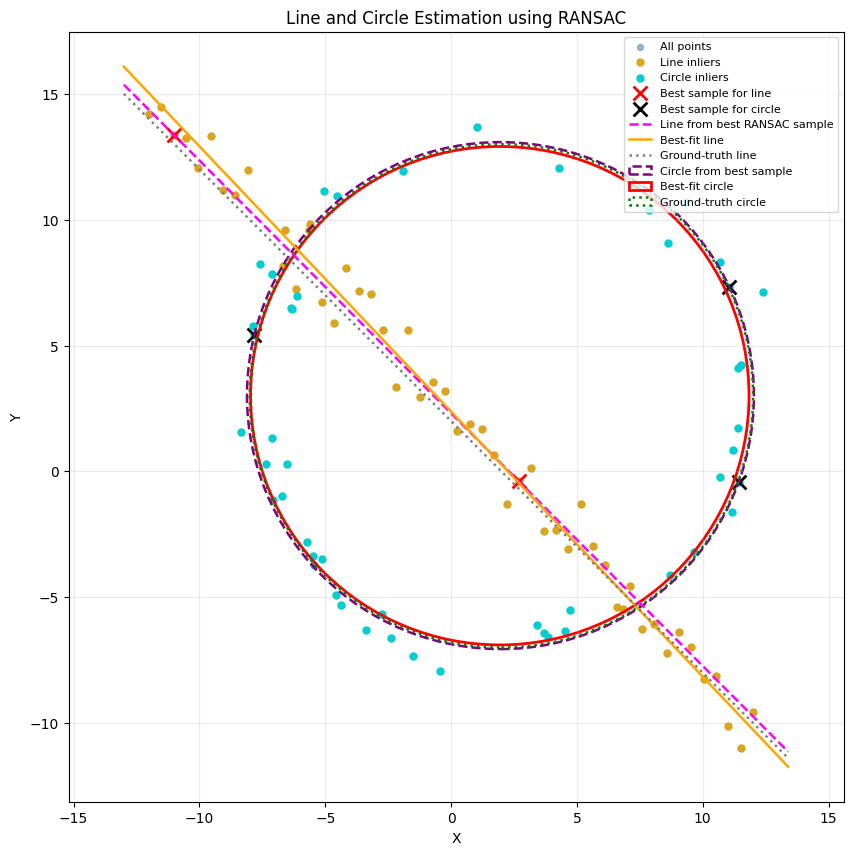

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy.optimize import minimize

np.random.seed(0)

# Generate the noisy circle and line
N = 100
half_n = N // 2
r_gt = 10
x0_gt, y0_gt = 2, 3

s = r_gt / 16
t = np.random.uniform(0, 2 * np.pi, half_n)
n = s * np.random.randn(half_n)
x = x0_gt + (r_gt + n) * np.cos(t)
y = y0_gt + (r_gt + n) * np.sin(t)
X_circ = np.column_stack((x, y))

s = 1.0
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m * x + b + s * np.random.randn(half_n)
X_line = np.column_stack((x, y))

X = np.vstack((X_circ, X_line))


# Line model: ax + by = d, with a^2 + b^2 = 1
def line_from_points(p1, p2):
    direction = p2 - p1
    normal = np.array([-direction[1], direction[0]])
    norm = np.linalg.norm(normal)

    if norm < 1e-10:
        return None

    normal = normal / norm
    d = np.dot(normal, p1)
    return normal[0], normal[1], d


def line_distances(points, model):
    a, b, d = model
    return np.abs(a * points[:, 0] + b * points[:, 1] - d)


def fit_line_tls(points):
    center = points.mean(axis=0)
    _, _, vh = np.linalg.svd(points - center, full_matrices=False)
    normal = vh[-1]
    normal = normal / np.linalg.norm(normal)
    d = np.dot(normal, center)
    return normal[0], normal[1], d


# (a) Estimate the line using custom RANSAC
line_threshold = 1.25
line_iterations = 3000
best_line_model = None
best_line_sample_model = None
best_line_sample_idx = None
best_line_mask = None
best_line_count = -1
best_line_error = np.inf

for _ in range(line_iterations):
    sample_idx = np.random.choice(len(X), 2, replace=False)
    model = line_from_points(X[sample_idx[0]], X[sample_idx[1]])

    if model is None:
        continue

    distances = line_distances(X, model)
    mask = distances < line_threshold
    count = np.sum(mask)
    error = np.sum(distances[mask] ** 2)

    if count > best_line_count or (
        count == best_line_count and error < best_line_error
    ):
        best_line_count = count
        best_line_error = error
        best_line_sample_model = model
        best_line_sample_idx = sample_idx
        best_line_mask = mask

line_inliers = best_line_mask.copy()

# Refine the line using total least squares on the consensus
for _ in range(5):
    if np.sum(line_inliers) < 2:
        break

    best_line_model = fit_line_tls(X[line_inliers])
    new_mask = line_distances(X, best_line_model) < line_threshold

    if np.array_equal(new_mask, line_inliers):
        break

    line_inliers = new_mask

best_line_model = fit_line_tls(X[line_inliers])
line_inliers = line_distances(X, best_line_model) < line_threshold

# (b) Remove line inliers and fit a circle to the remaining points
X_remaining = X[~line_inliers]


def circle_from_three_points(points):
    p1, p2, p3 = points
    matrix = 2 * np.array([p2 - p1, p3 - p1])
    rhs = np.array([
        np.dot(p2, p2) - np.dot(p1, p1),
        np.dot(p3, p3) - np.dot(p1, p1)
    ])

    if abs(np.linalg.det(matrix)) < 1e-6:
        return None

    center = np.linalg.solve(matrix, rhs)
    radius = np.linalg.norm(p1 - center)
    return center[0], center[1], radius


def circle_errors(points, model):
    cx, cy, radius = model
    distances = np.sqrt(
        (points[:, 0] - cx) ** 2 +
        (points[:, 1] - cy) ** 2
    )
    return np.abs(distances - radius)


circle_threshold = 1.2
circle_iterations = 5000
best_circle_sample_model = None
best_circle_sample_idx = None
best_circle_mask = None
best_circle_count = -1
best_circle_error = np.inf

for _ in range(circle_iterations):
    sample_idx = np.random.choice(len(X_remaining), 3, replace=False)
    model = circle_from_three_points(X_remaining[sample_idx])

    if model is None:
        continue

    errors = circle_errors(X_remaining, model)
    mask = errors < circle_threshold
    count = np.sum(mask)
    error = np.sum(errors[mask] ** 2)

    if count > best_circle_count or (
        count == best_circle_count and error < best_circle_error
    ):
        best_circle_count = count
        best_circle_error = error
        best_circle_sample_model = model
        best_circle_sample_idx = sample_idx
        best_circle_mask = mask

circle_inliers = best_circle_mask.copy()

# Optimize the circle parameters using its RANSAC inliers
def circle_cost(params, points):
    cx, cy, radius = params
    distances = np.sqrt(
        (points[:, 0] - cx) ** 2 +
        (points[:, 1] - cy) ** 2
    )
    return np.sum((distances - radius) ** 2)


initial_circle = np.array(best_circle_sample_model, dtype=float)
optimization = minimize(
    circle_cost,
    initial_circle,
    args=(X_remaining[circle_inliers],),
    method="L-BFGS-B",
    bounds=[(None, None), (None, None), (1e-6, None)]
)

best_circle_model = optimization.x
cx_fit, cy_fit, r_fit = best_circle_model

# Results
a_sample, b_sample, d_sample = best_line_sample_model
a_fit, b_fit, d_fit = best_line_model
cx_ransac, cy_ransac, r_ransac = best_circle_sample_model

print("LINE ESTIMATION")
print(f"Line RANSAC threshold: {line_threshold}")
print(f"Number of line inliers: {np.sum(line_inliers)}")
print(f"RANSAC sample line: {a_sample:.4f}x + {b_sample:.4f}y = {d_sample:.4f}")
print(f"Best-fit line:      {a_fit:.4f}x + {b_fit:.4f}y = {d_fit:.4f}")
print(f"Normal length: {np.sqrt(a_fit**2 + b_fit**2):.4f}")

print("\nCIRCLE ESTIMATION")
print(f"Circle RANSAC threshold: {circle_threshold}")
print(f"Number of circle inliers: {np.sum(circle_inliers)}")
print(f"RANSAC circle center: ({cx_ransac:.3f}, {cy_ransac:.3f})")
print(f"RANSAC circle radius: {r_ransac:.3f}")
print(f"Optimized circle center: ({cx_fit:.3f}, {cy_fit:.3f})")
print(f"Optimized circle radius: {r_fit:.3f}")


# (c) Plot all points, samples, inliers, and estimated models
fig, ax = plt.subplots(figsize=(10, 10))

ax.scatter(X[:, 0], X[:, 1], s=18, color="steelblue",
           alpha=0.55, label="All points")
ax.scatter(X[line_inliers, 0], X[line_inliers, 1], s=25,
           color="goldenrod", label="Line inliers")
ax.scatter(X_remaining[circle_inliers, 0],
           X_remaining[circle_inliers, 1], s=25,
           color="darkturquoise", label="Circle inliers")

ax.scatter(X[best_line_sample_idx, 0],
           X[best_line_sample_idx, 1], marker="x", s=100,
           color="red", linewidths=2, label="Best sample for line")

circle_sample_points = X_remaining[best_circle_sample_idx]
ax.scatter(circle_sample_points[:, 0], circle_sample_points[:, 1],
           marker="x", s=100, color="black", linewidths=2,
           label="Best sample for circle")

x_plot = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 400)


def draw_line(model, style, label, color):
    a, b, d = model
    if abs(b) > 1e-8:
        ax.plot(x_plot, (d - a * x_plot) / b,
                linestyle=style, color=color, linewidth=1.8,
                label=label)
    else:
        ax.axvline(d / a, linestyle=style, color=color,
                   linewidth=1.8, label=label)


draw_line(best_line_sample_model, "--",
          "Line from best RANSAC sample", "magenta")
draw_line(best_line_model, "-",
          "Best-fit line", "orange")
draw_line((1 / np.sqrt(2), 1 / np.sqrt(2), 2 / np.sqrt(2)),
          ":", "Ground-truth line", "gray")

ax.add_patch(Circle((cx_ransac, cy_ransac), r_ransac,
                    fill=False, linestyle="--", linewidth=1.8,
                    color="purple", label="Circle from best sample"))
ax.add_patch(Circle((cx_fit, cy_fit), r_fit,
                    fill=False, linewidth=2,
                    color="red", label="Best-fit circle"))
ax.add_patch(Circle((x0_gt, y0_gt), r_gt,
                    fill=False, linestyle=":", linewidth=1.8,
                    color="green", label="Ground-truth circle"))

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_title("Line and Circle Estimation using RANSAC")
ax.set_aspect("equal", adjustable="datalim")
ax.grid(True, alpha=0.25)
ax.legend(fontsize=8, loc="upper right")
plt.show()

What will happen if we fit the circle first?

RANSAC may identify the circle formed by the circular points and remove its inliers. We can then fit the line to the remaining points.
However, some line points may also lie close to the circle circumference and may be incorrectly classified as circle inliers. Removing these points can affect the subsequent line estimation. The result depends on the selected error thresholds, the noise, and the number of inliers for each model. Since the circle requires three sampled points while the line requires only two, circle estimation also generally requires more random samples to obtain a reliable model when the inlier ratios are similar.